## Sinh dữ liệu

### Khởi tạo Spark

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

spark = (
    SparkSession.builder
    .appName("Phase01-SparkExecution")
    .master("local[4]")
    .config("spark.sql.shuffle.partitions", "4")
    # tắt Adaptive Query Execution (AQE) (cơ chế giúp Spark điều chỉnh kế hoạch thực thi trong lúc chạy)
    # tắt AQE để dễ quan sát execution plan và số lượng task
    .config("spark.sql.adaptive.enabled", "false")  
    .getOrCreate()
)

sc = spark.sparkContext

26/11/25 10:11:35 WARN Utils: Your hostname, Thor-2.local resolves to a loopback address: 127.0.0.1; using 10.40.69.61 instead (on interface en0)
26/11/25 10:11:35 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/25 10:11:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/25 10:11:36 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


### Sinh dữ liệu

In [2]:
import csv
from pathlib import Path
from datetime import datetime, timedelta

root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

orders_path = raw_dir / "orders.csv"

with orders_path.open("w", newline="") as f:
    writer = csv.writer(f)

    writer.writerow([
        "order_id",
        "customer_id",
        "order_ts",
        "status"
    ])

    for i in range(1, 101):
        writer.writerow([
            f"O{i:04d}",
            f"C{i % 10 + 1:03d}",
            datetime(2026, 1, 1) + timedelta(hours=i),
            "cancelled" if i % 4 == 0 else "completed"
        ])

print(orders_path)

/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/orders.csv


## Đọc dữ liệu vào Spark

### Định nghĩa schema

Schema là cấu trúc mô tả tên cột, kiểu dữ liệu và thuộc tính nullable.
| Thành phần | Ý nghĩa |
|---|---|
| `StructType` | Cấu trúc của một bản ghi |
| `StructField` | Định nghĩa một trường |
| `StringType()` | Kiểu chuỗi |
| `TimestampType()` | Kiểu ngày giờ |
| `False` | Khai báo trường không nullable (không chấp nhận giá trị `null`) |

In [3]:
order_schema = StructType([ 
    StructField("order_id", StringType(), False),   
    StructField("customer_id", StringType(), False),
    StructField("order_ts", TimestampType(), False),
    StructField("status", StringType(), False)
])

### Đọc file CSV

In [4]:
orders = (
    spark.read
    .option("header", True)
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(order_schema)
    .csv(str(orders_path))
)

orders.printSchema()

root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_ts: timestamp (nullable = true)
 |-- status: string (nullable = true)



| Bước | Infer Schema | Explicit Schema |
|---|---|---|
| 1 | CSV | CSV |
| ↓ | ↓ | ↓ |
| 2 | Đọc để suy luận kiểu | Schema có sẵn |
| ↓ | ↓ | ↓ |
| 3 | Schema | Đọc và xử lý dữ liệu |
| ↓ | ↓ | |
| 4 | Đọc và xử lý dữ liệu | |

Trong Data Engineering, **explicit schema** thường được ưu tiên vì tránh chi phí suy luận schema và kiểm soát được kiểu dữ liệu đầu vào.

| Transformation | Action |
|---|---|
| `select()` | `show()` |
| `filter()` | `count()` |
| `withColumn()` | `collect()` |
| `groupBy().agg()` | `take()` |
| `join()` | `first()` |
| `orderBy()` | `write.save()` |
| `repartition()` | `toPandas()` |

**Transformation** tạo ra DataFrame mới và mở rộng kế hoạch xử lý.

**Action** yêu cầu Spark thực thi tính toán để trả về kết quả hoặc ghi dữ liệu.

In [14]:
completed_orders = orders.filter(
    F.col("status") == "completed"
)

In [15]:
selected_orders = completed_orders.select(
    "order_id",
    "customer_id"
)

In [16]:
customer_summary = (
    selected_orders
    .groupBy("customer_id")
    .agg(
        F.count("order_id").alias("total_orders")
    )
)

In [17]:
customer_summary.show()

+-----------+------------+
|customer_id|total_orders|
+-----------+------------+
|       C007|           5|
|       C001|           5|
|       C005|           5|
|       C009|           5|
|       C002|          10|
|       C004|          10|
|       C003|           5|
|       C006|          10|
|       C008|          10|
|       C010|          10|
+-----------+------------+



In [18]:
customer_summary.show()

customer_summary.count()

customer_summary.collect()

+-----------+------------+
|customer_id|total_orders|
+-----------+------------+
|       C007|           5|
|       C001|           5|
|       C005|           5|
|       C009|           5|
|       C002|          10|
|       C004|          10|
|       C003|           5|
|       C006|          10|
|       C008|          10|
|       C010|          10|
+-----------+------------+



[Row(customer_id='C007', total_orders=5),
 Row(customer_id='C001', total_orders=5),
 Row(customer_id='C005', total_orders=5),
 Row(customer_id='C009', total_orders=5),
 Row(customer_id='C002', total_orders=10),
 Row(customer_id='C004', total_orders=10),
 Row(customer_id='C003', total_orders=5),
 Row(customer_id='C006', total_orders=10),
 Row(customer_id='C008', total_orders=10),
 Row(customer_id='C010', total_orders=10)]

### Execution plan

In [19]:
customer_summary.explain()

== Physical Plan ==
*(2) HashAggregate(keys=[customer_id#1], functions=[count(order_id#0)])
+- Exchange hashpartitioning(customer_id#1, 4), ENSURE_REQUIREMENTS, [plan_id=244]
   +- *(1) HashAggregate(keys=[customer_id#1], functions=[partial_count(order_id#0)])
      +- *(1) Project [order_id#0, customer_id#1]
         +- *(1) Filter (isnotnull(status#3) AND (status#3 = completed))
            +- FileScan csv [order_id#0,customer_id#1,status#3] Batched: false, DataFilters: [isnotnull(status#3), (status#3 = completed)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/o..., PartitionFilters: [], PushedFilters: [IsNotNull(status), EqualTo(status,completed)], ReadSchema: struct<order_id:string,customer_id:string,status:string>




| Physical Plan | Ý nghĩa |
|:---:|---|
| **HashAggregate** | Tổng hợp kết quả cuối cùng |
| ↑ | |
| **Exchange** | Shuffle dữ liệu |
| ↑ | |
| **HashAggregate** | Tổng hợp cục bộ |
| ↑ | |
| **Project** | Chọn các cột cần thiết |
| ↑ | |
| **Filter** | Lọc completed orders |
| ↑ | |
| **FileScan CSV** | Đọc `orders.csv` |

**Đọc Physical Plan từ dưới lên trên.** 

In [21]:
status_summary = (
    orders
    .groupBy("status")
    .agg(
        F.count("order_id").alias("total_orders")
    )
)

status_summary.show()

+---------+------------+
|   status|total_orders|
+---------+------------+
|completed|          75|
|cancelled|          25|
+---------+------------+



In [22]:
actual = {
    row["status"]: row["total_orders"]
    for row in status_summary.collect()
}

assert actual == {
    "completed": 75,
    "cancelled": 25
}

assert orders.count() == 100

assert completed_orders.count() == 75

assert customer_summary.count() == 10

print("All tests passed!")

All tests passed!


### Driver và Executor

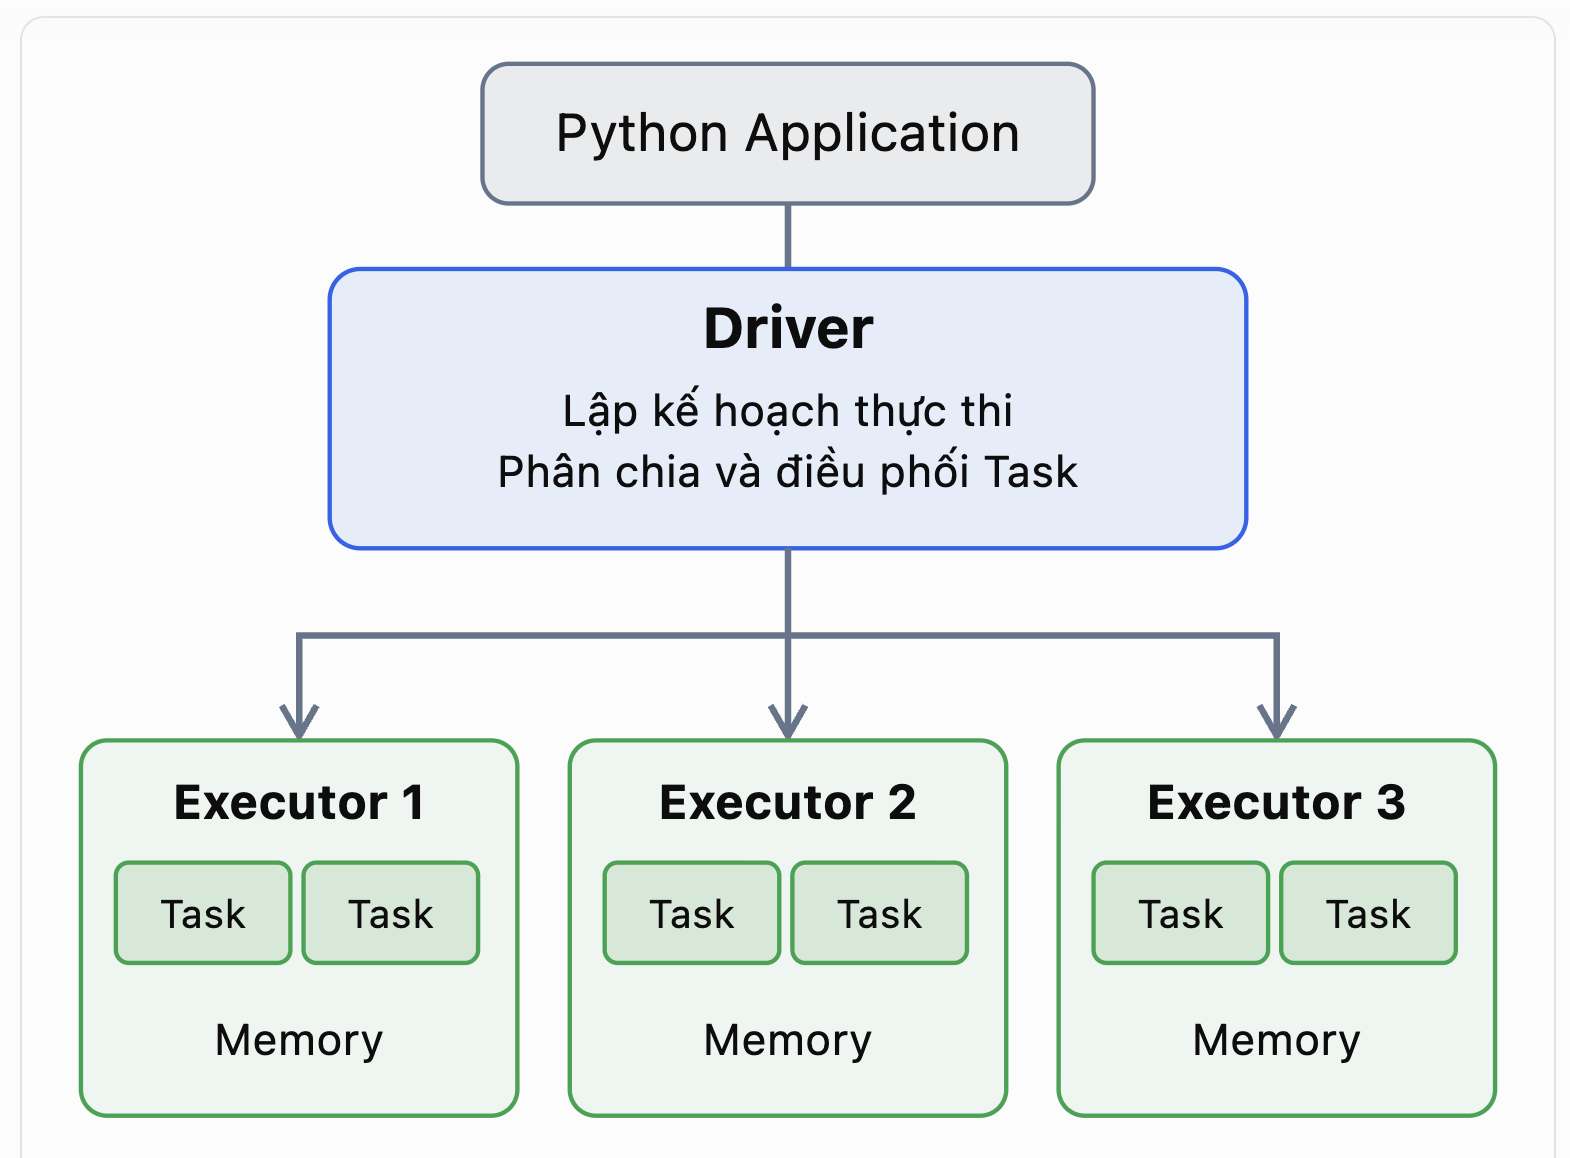

| Thành phần | Vai trò |
|---|---|
| Driver | Điều phối toàn bộ Spark Application |
| Executor | Thực thi task và lưu dữ liệu trung gian |
| Cluster Manager | Cấp phát tài nguyên cho application |
| Worker Node | Máy cung cấp tài nguyên tính toán, nơi Executor có thể chạy |

Hiểu đơn giản, **Driver** quyết định cần làm gì và phân chia công việc. **Executor** thực hiện công việc được giao.

### Application, Job, Stage, Task

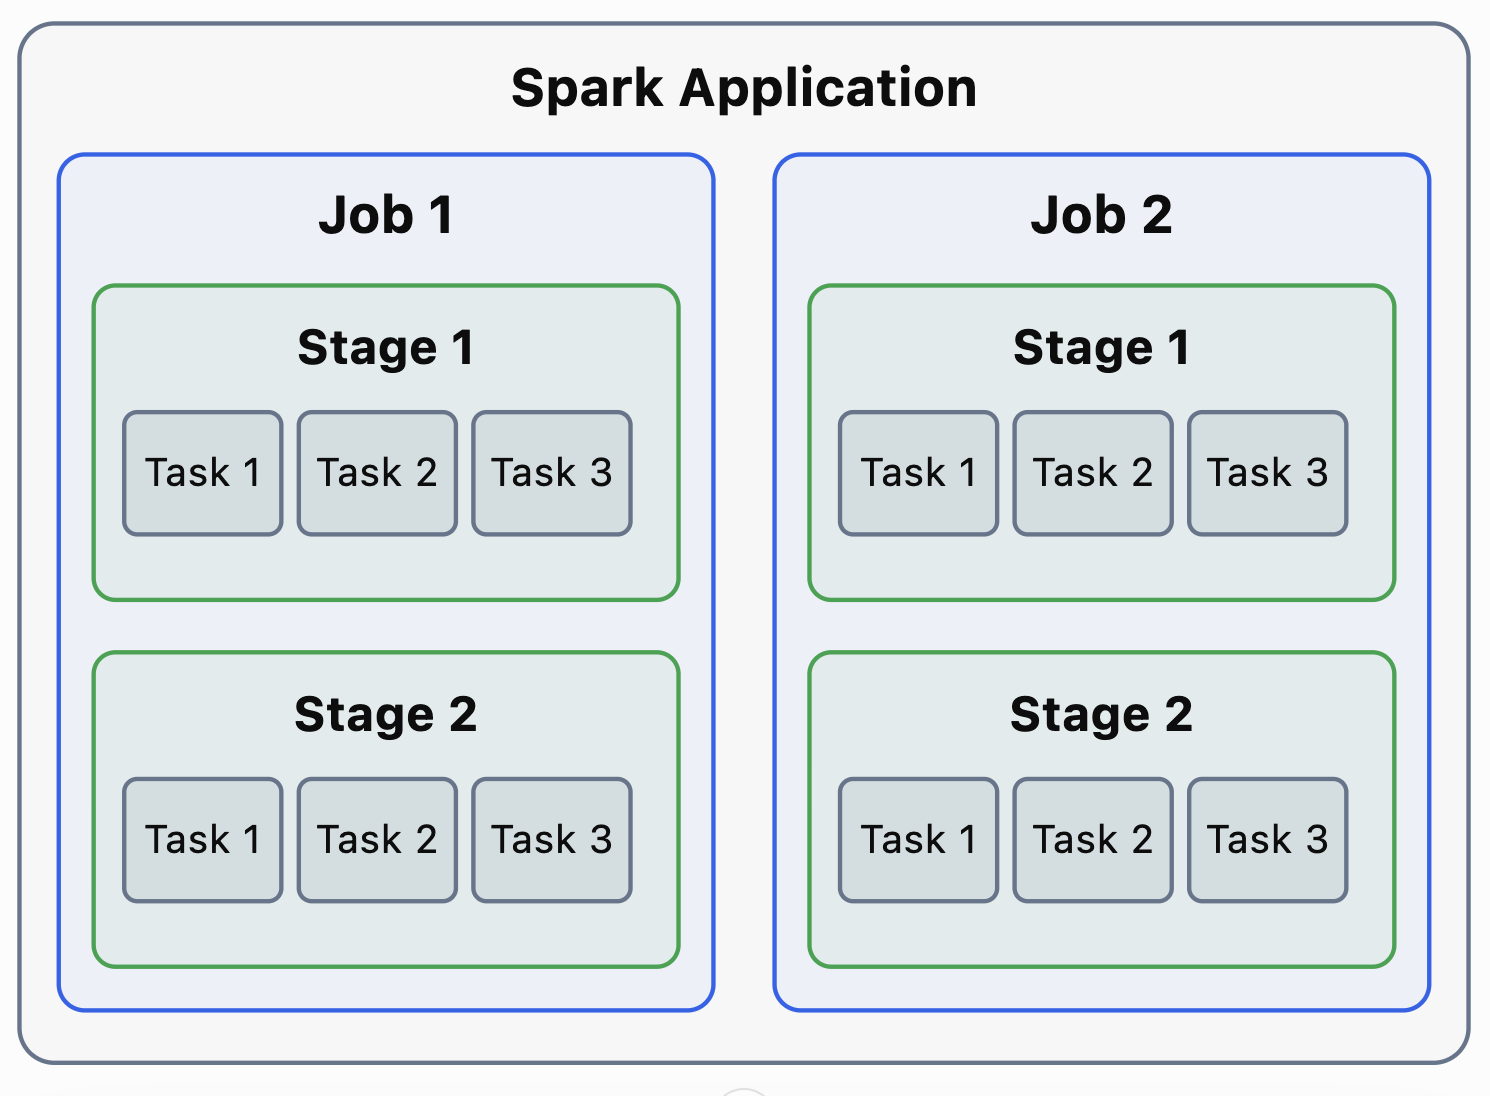

| Khái niệm | Giải thích |
|---|---|
| Application | Toàn bộ ứng dụng Spark đang chạy |
| Job | Công việc tính toán được kích hoạt khi cần thực thi |
| Stage | Nhóm task có thể thực thi mà không cần shuffle ở giữa |
| Task | Đơn vị thực thi nhỏ nhất, xử lý một partition của stage |

Cần nhớ rằng **một action có thể tạo ra một hoặc nhiều Job**, tùy kế hoạch thực thi.

### Kiểm tra partition hiện tại

In [23]:
print("Input partitions:", orders.rdd.getNumPartitions())

print(
    "Shuffle partitions:",
    spark.conf.get("spark.sql.shuffle.partitions")
)

Input partitions: 1
Shuffle partitions: 4


### Tạo df gồm 4 partition

In [24]:
demo = spark.range(
    start=0,
    end=1000,
    step=1,
    numPartitions=4
)

demo = demo.withColumn(
    "customer_id",
    F.col("id") % 10
)

print("Partitions:", demo.rdd.getNumPartitions())

demo.show(5)

Partitions: 4
+---+-----------+
| id|customer_id|
+---+-----------+
|  0|          0|
|  1|          1|
|  2|          2|
|  3|          3|
|  4|          4|
+---+-----------+
only showing top 5 rows



### Narrow Transformation

In [25]:
filtered = demo.filter(F.col("id") % 2 == 0)

sc.setJobGroup(
    "narrow_demo",
    "Narrow transformation - Filter"
)

filtered.count()

500

### Wide Transformation và Shuffle

In [26]:
summary = (
    demo
    .filter(F.col("id") % 2 == 0)
    .groupBy("customer_id")
    .agg(
        F.count("*").alias("total_orders")
    )
)

summary.explain()

== Physical Plan ==
*(2) HashAggregate(keys=[customer_id#164L], functions=[count(1)])
+- Exchange hashpartitioning(customer_id#164L, 4), ENSURE_REQUIREMENTS, [plan_id=510]
   +- *(1) HashAggregate(keys=[customer_id#164L], functions=[partial_count(1)])
      +- *(1) Project [(id#162L % 10) AS customer_id#164L]
         +- *(1) Filter ((id#162L % 2) = 0)
            +- *(1) Range (0, 1000, step=1, splits=4)




In [27]:
sc.setJobGroup(
    "wide_demo",
    "Wide transformation - GroupBy"
)

result = summary.collect()

print(result)

[Row(customer_id=2, total_orders=100), Row(customer_id=4, total_orders=100), Row(customer_id=8, total_orders=100), Row(customer_id=0, total_orders=100), Row(customer_id=6, total_orders=100)]


Shuffle thường tốn tài nguyên vì liên quan đến serialization, bộ nhớ, disk I/O và truyền dữ liệu qua mạng nếu chạy trên cluster.

### DAG

DAG – Directed Acyclic Graph là đồ thị có hướng không có chu trình, biểu diễn sự phụ thuộc giữa các phép tính.

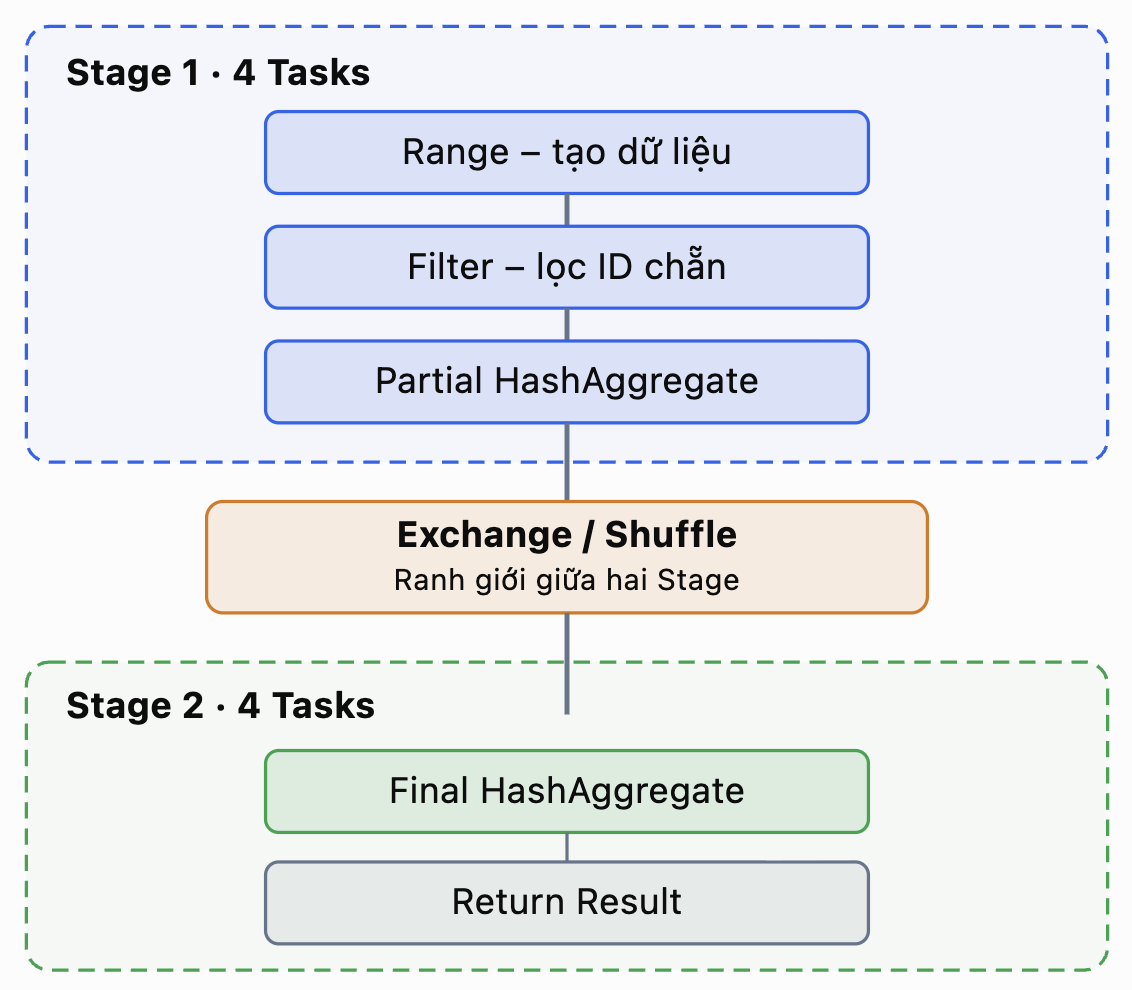

### Thay đổi số shuffle partition

In [28]:
spark.conf.set("spark.sql.shuffle.partitions", "8")

summary_v2 = (
    demo
    .filter(F.col("id") % 2 == 0)
    .groupBy("customer_id")
    .agg(
        F.count("*").alias("total_orders")
    )
)

sc.setJobGroup(
    "partition_demo",
    "GroupBy with 8 shuffle partitions"
)

result_v2 = summary_v2.collect()

summary_v2.explain()

== Physical Plan ==
*(2) HashAggregate(keys=[customer_id#164L], functions=[count(1)])
+- Exchange hashpartitioning(customer_id#164L, 8), ENSURE_REQUIREMENTS, [plan_id=545]
   +- *(1) HashAggregate(keys=[customer_id#164L], functions=[partial_count(1)])
      +- *(1) Project [(id#162L % 10) AS customer_id#164L]
         +- *(1) Filter ((id#162L % 2) = 0)
            +- *(1) Range (0, 1000, step=1, splits=4)




Bạn có thể thấy thay đổi spark.sql.shuffle.partitions không làm thay đổi số partition đầu vào. Nó thay đổi số partition được sử dụng ở bước shuffle tương ứng.

Nhiều task hơn cũng chưa chắc chạy nhanh hơn, vì còn chi phí lập lịch và giới hạn số luồng thực thi.

In [29]:
actual = {
    row["customer_id"]: row["total_orders"]
    for row in result
}

actual_v2 = {
    row["customer_id"]: row["total_orders"]
    for row in result_v2
}

expected = {
    0: 100,
    2: 100,
    4: 100,
    6: 100,
    8: 100
}

assert demo.count() == 1000
assert demo.rdd.getNumPartitions() == 4
assert filtered.count() == 500

assert actual == expected
assert actual_v2 == expected
assert actual == actual_v2

print("All 6 tests passed!")

All 6 tests passed!


In [ ]:
spark.conf.set("spark.sql.shuffle.partitions", "4") # Khôi phục số shuffle partition về 4

sc.setLocalProperty("spark.jobGroup.id", None)  #   Xóa ID của nhóm Job cũ
sc.setLocalProperty("spark.job.description", None)  #  Xóa mô tả Job cũ
sc.setLocalProperty("spark.job.interruptOnCancel", None)    # Xóa cấu hình ngắt task khi hủy Job

print("Reset configuration successfully!")

Reset configuration successfully!


In [32]:
query = (
    orders
    .filter(F.col("status") == "completed")
    .groupBy("customer_id")
    .agg(F.count("order_id").alias("total_orders"))
)

query.collect()

[Row(customer_id='C007', total_orders=5),
 Row(customer_id='C001', total_orders=5),
 Row(customer_id='C005', total_orders=5),
 Row(customer_id='C009', total_orders=5),
 Row(customer_id='C002', total_orders=10),
 Row(customer_id='C004', total_orders=10),
 Row(customer_id='C003', total_orders=5),
 Row(customer_id='C006', total_orders=10),
 Row(customer_id='C008', total_orders=10),
 Row(customer_id='C010', total_orders=10)]

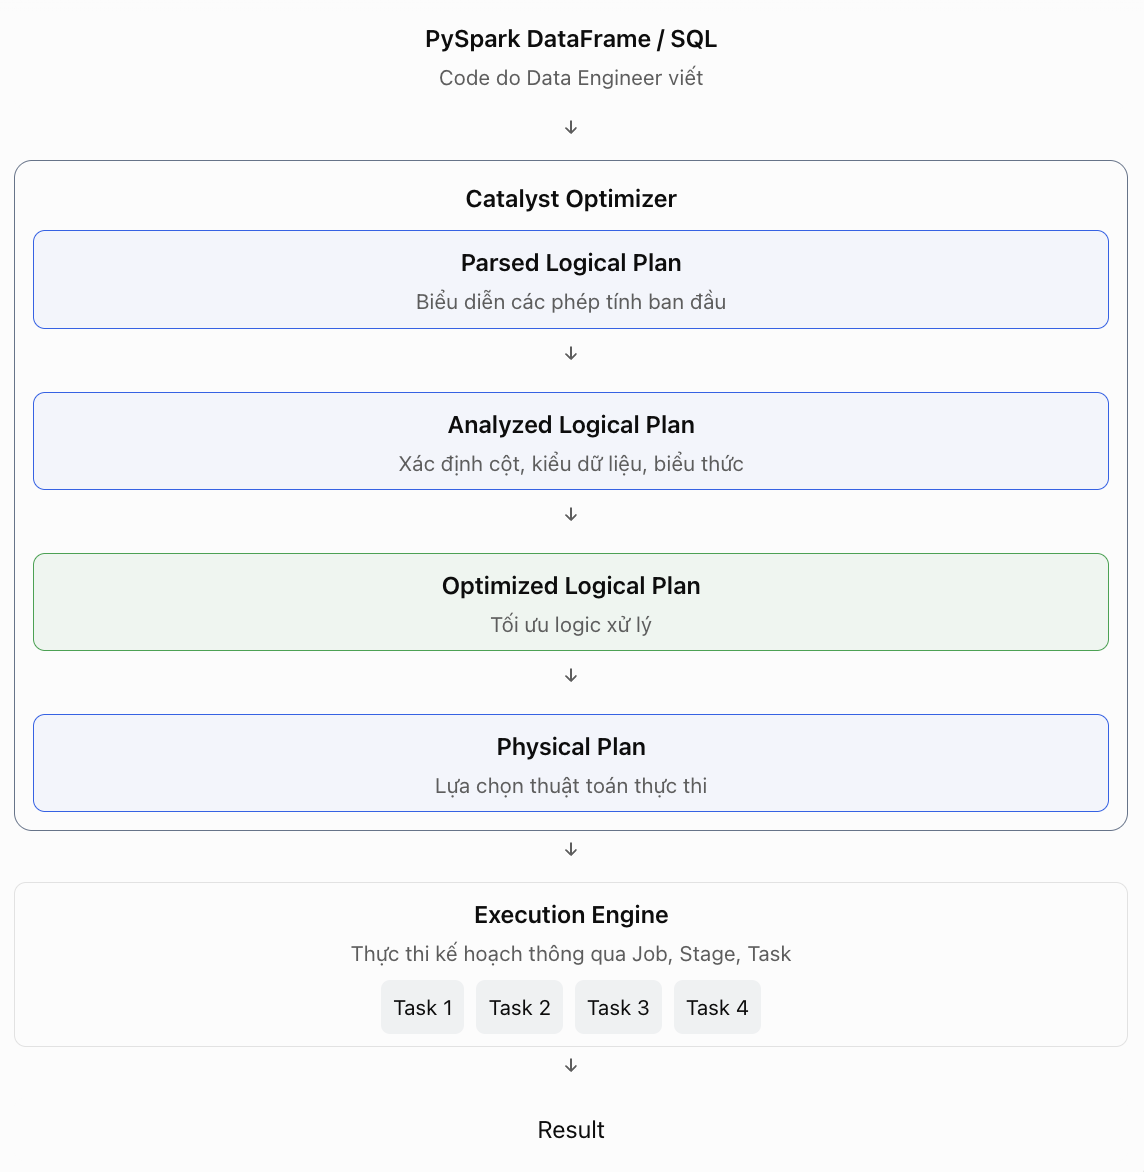

| Thành phần | Câu hỏi cần giải quyết |
|---|---|
| Logical Plan | Cần xử lý dữ liệu như thế nào về mặt logic? |
| Optimized Logical Plan | Có thể đơn giản hóa hoặc cải thiện logic không? |
| Physical Plan | Sử dụng thuật toán nào để thực hiện? |
| Execution Engine | Làm thế nào để thực thi trên các tài nguyên hiện có? |

In [33]:
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.shuffle.partitions", "4")

query = (
    orders
    .filter(F.col("status") == "completed")
    .select("order_id", "customer_id")
    .groupBy("customer_id")
    .agg(F.count("order_id").alias("total_orders"))
)

query.explain("extended")

== Parsed Logical Plan ==
'Aggregate ['customer_id], ['customer_id, count('order_id) AS total_orders#232]
+- Project [order_id#0, customer_id#1]
   +- Filter (status#3 = completed)
      +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Analyzed Logical Plan ==
customer_id: string, total_orders: bigint
Aggregate [customer_id#1], [customer_id#1, count(order_id#0) AS total_orders#232L]
+- Project [order_id#0, customer_id#1]
   +- Filter (status#3 = completed)
      +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Optimized Logical Plan ==
Aggregate [customer_id#1], [customer_id#1, count(order_id#0) AS total_orders#232L]
+- Project [order_id#0, customer_id#1]
   +- Filter (isnotnull(status#3) AND (status#3 = completed))
      +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Physical Plan ==
*(2) HashAggregate(keys=[customer_id#1], functions=[count(order_id#0)], output=[customer_id#1, total_orders#232L])
+- Exchange hashpartitioning(cust

| Kỹ thuật | Ý nghĩa |
|---|---|
| Column Pruning | Loại bỏ cột không cần thiết |
| Predicate Pushdown | Đẩy điều kiện lọc xuống nguồn dữ liệu khi được hỗ trợ |
| Constant Folding | Tính trước các biểu thức hằng số |
| Filter Pushdown | Đẩy phép lọc xuống gần nguồn dữ liệu hơn |
| Projection Pruning | Loại bỏ các biểu thức đầu ra không cần thiết |

-- Physical Plan --

Trong đó:
- HashAggregate: sử dụng cơ chế tổng hợp dựa trên hash.
- Exchange: phân phối lại dữ liệu; trong ví dụ này là shuffle.
- hashpartitioning(customer_id, 4): phân phối dữ liệu thành 4 partition dựa trên hash của customer_id.
- FileScan: đọc dữ liệu từ file.
- *(1) và *(2): ID của các nhóm Whole-Stage Code Generation, không phải Stage ID trong Spark UI.
Physical Plan cho biết Spark thực hiện query bằng cách nào, còn DAG của các stage cho biết công việc được chia nhỏ và điều phối như thế nào.

In [34]:
query.explain("formatted")

== Physical Plan ==
* HashAggregate (6)
+- Exchange (5)
   +- * HashAggregate (4)
      +- * Project (3)
         +- * Filter (2)
            +- Scan csv  (1)


(1) Scan csv 
Output [3]: [order_id#0, customer_id#1, status#3]
Batched: false
Location: InMemoryFileIndex [file:/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/orders.csv]
PushedFilters: [IsNotNull(status), EqualTo(status,completed)]
ReadSchema: struct<order_id:string,customer_id:string,status:string>

(2) Filter [codegen id : 1]
Input [3]: [order_id#0, customer_id#1, status#3]
Condition : (isnotnull(status#3) AND (status#3 = completed))

(3) Project [codegen id : 1]
Output [2]: [order_id#0, customer_id#1]
Input [3]: [order_id#0, customer_id#1, status#3]

(4) HashAggregate [codegen id : 1]
Input [2]: [order_id#0, customer_id#1]
Keys [1]: [customer_id#1]
Functions [1]: [partial_count(order_id#0)]
Aggregate Attributes [1]: [count#235L]
Results [2]: [customer_id#1, count#236L]

(5) Exchange
Input [2]: [customer_id

| Keyword | Ý nghĩa |
|---|---|
| `ReadSchema` | Schema các cột cần đọc |
| `PushedFilters` | Điều kiện lọc được chuyển xuống data source |
| `DataFilters` | Điều kiện lọc dữ liệu liên quan đến scan |
| `Exchange` | Phân phối lại dữ liệu |
| `HashAggregate` | Tổng hợp dữ liệu |
| `Input` / `Output` | Các cột đầu vào và đầu ra của operator |

### Spark có tối ưu thứ tự viết code không?
Viết hai query khác nhau nhưng có cùng logic nghiệp vụ.

In [35]:
# Cách A: Filter trước, Select sau
query_a = (
    orders
    .filter(F.col("status") == "completed")
    .select("customer_id")
)

# Cách B: Select trước, Filter sau
query_b = (
    orders
    .select("customer_id", "status")
    .filter(F.col("status") == "completed")
    .select("customer_id")
)

In [36]:
print("===== QUERY A =====")
query_a.explain("extended")

print("===== QUERY B =====")
query_b.explain("extended")

===== QUERY A =====
== Parsed Logical Plan ==
'Project ['customer_id]
+- Filter (status#3 = completed)
   +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Analyzed Logical Plan ==
customer_id: string
Project [customer_id#1]
+- Filter (status#3 = completed)
   +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Optimized Logical Plan ==
Project [customer_id#1]
+- Filter (isnotnull(status#3) AND (status#3 = completed))
   +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv

== Physical Plan ==
*(1) Project [customer_id#1]
+- *(1) Filter (isnotnull(status#3) AND (status#3 = completed))
   +- FileScan csv [customer_id#1,status#3] Batched: false, DataFilters: [isnotnull(status#3), (status#3 = completed)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/o..., PartitionFilters: [], PushedFilters: [IsNotNull(status), EqualTo(status,completed)], ReadSchema: struct<customer_id:strin

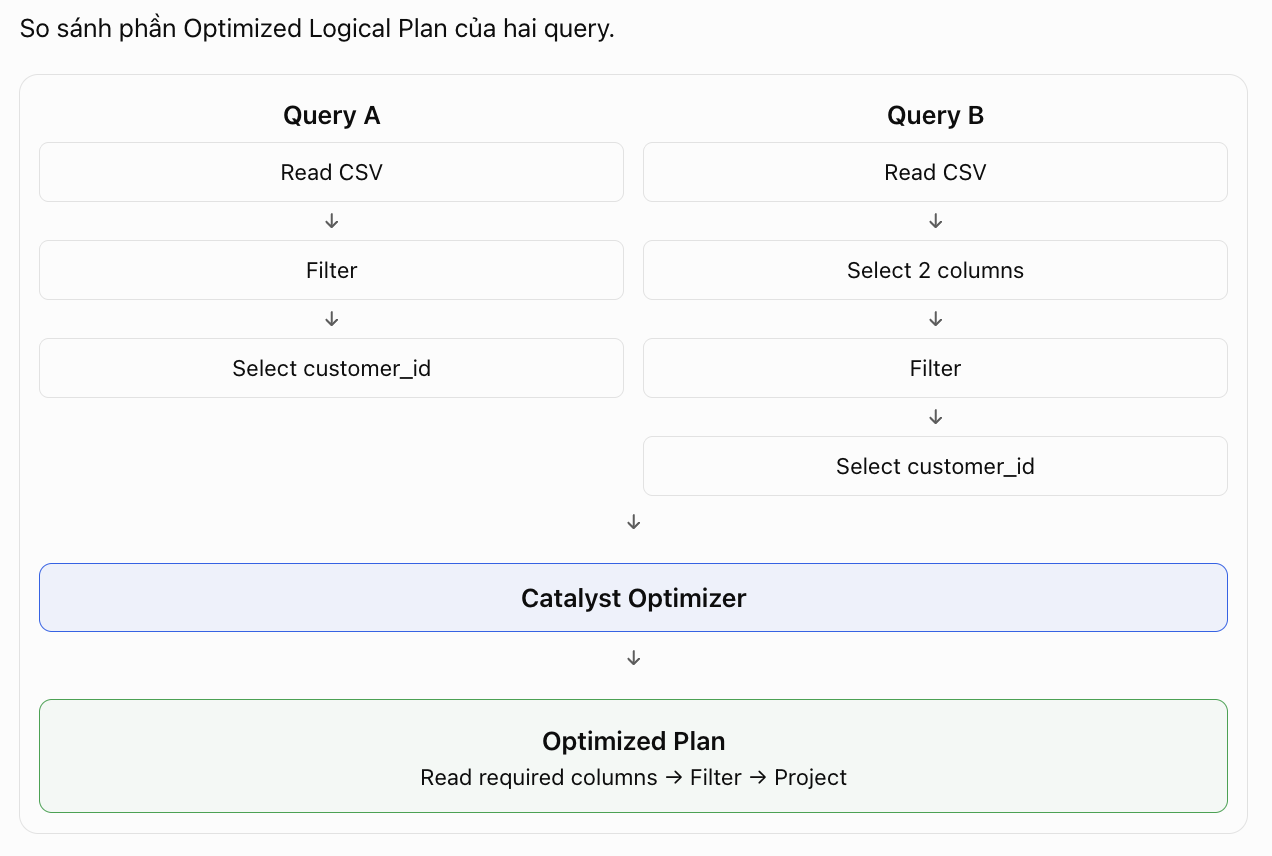

Hai query có thể được Catalyst tối ưu thành kế hoạch tương đương.

Điều này giải thích vì sao viết filter() trước select() không phải lúc nào cũng nhanh hơn. Với những phép biến đổi mà Catalyst hiểu được, Spark có thể tự sắp xếp lại kế hoạch.

### Constant Folding
Constant Folding là kĩ thuật tính trước  những biểu thức có giá trị cố định

In [37]:
constant_demo = spark.range(10).select(
    "id",
    (F.lit(100) * F.lit(20)).alias("value")
)

constant_demo.explain("extended")

constant_demo.show()

== Parsed Logical Plan ==
'Project ['id, (100 * 20) AS value#244]
+- Range (0, 10, step=1, splits=Some(4))

== Analyzed Logical Plan ==
id: bigint, value: int
Project [id#242L, (100 * 20) AS value#244]
+- Range (0, 10, step=1, splits=Some(4))

== Optimized Logical Plan ==
Project [id#242L, 2000 AS value#244]
+- Range (0, 10, step=1, splits=Some(4))

== Physical Plan ==
*(1) Project [id#242L, 2000 AS value#244]
+- *(1) Range (0, 10, step=1, splits=4)

+---+-----+
| id|value|
+---+-----+
|  0| 2000|
|  1| 2000|
|  2| 2000|
|  3| 2000|
|  4| 2000|
|  5| 2000|
|  6| 2000|
|  7| 2000|
|  8| 2000|
|  9| 2000|
+---+-----+



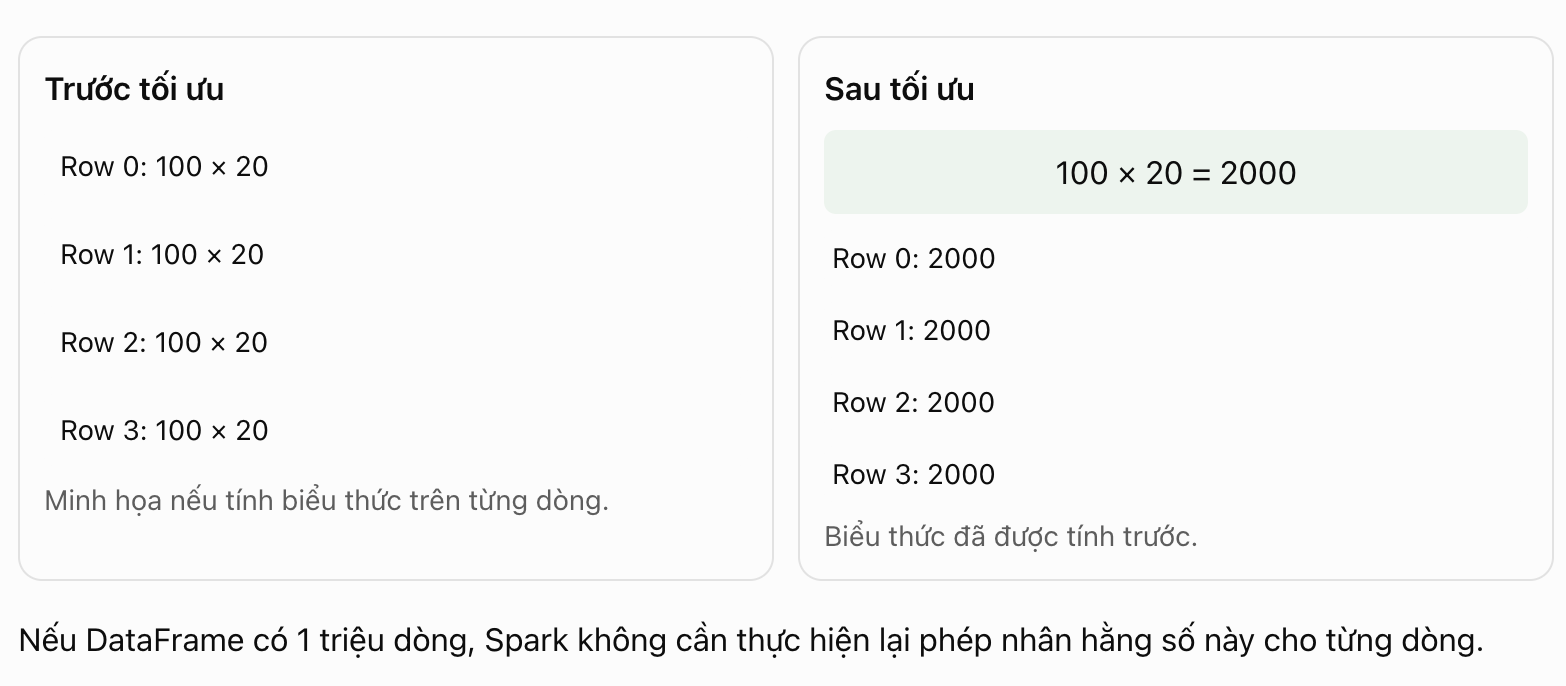

### Partial Aggregation

In [38]:
sc.setJobGroup(
    "partial_aggregation",
    "Phase 1C - Partial Aggregation"
)

query_result = query.collect()

query.explain("formatted")

print(query_result)

== Physical Plan ==
* HashAggregate (6)
+- Exchange (5)
   +- * HashAggregate (4)
      +- * Project (3)
         +- * Filter (2)
            +- Scan csv  (1)


(1) Scan csv 
Output [3]: [order_id#0, customer_id#1, status#3]
Batched: false
Location: InMemoryFileIndex [file:/Volumes/Lexar E6/Code/spark-analytics-performance-lab/data/raw/orders.csv]
PushedFilters: [IsNotNull(status), EqualTo(status,completed)]
ReadSchema: struct<order_id:string,customer_id:string,status:string>

(2) Filter [codegen id : 1]
Input [3]: [order_id#0, customer_id#1, status#3]
Condition : (isnotnull(status#3) AND (status#3 = completed))

(3) Project [codegen id : 1]
Output [2]: [order_id#0, customer_id#1]
Input [3]: [order_id#0, customer_id#1, status#3]

(4) HashAggregate [codegen id : 1]
Input [2]: [order_id#0, customer_id#1]
Keys [1]: [customer_id#1]
Functions [1]: [partial_count(order_id#0)]
Aggregate Attributes [1]: [count#235L]
Results [2]: [customer_id#1, count#236L]

(5) Exchange
Input [2]: [customer_id

### Các chế độ của `explain()`

| Code | Nội dung |
|---|---|
| `df.explain()` | Physical Plan |
| `df.explain("simple")` | Physical Plan |
| `df.explain("extended")` | Logical Plan và Physical Plan |
| `df.explain("formatted")` | Physical Plan kèm chi tiết operator |
| `df.explain("cost")` | Logical Plan đã tối ưu và thống kê nếu có |
| `df.explain("codegen")` | Thông tin generated code nếu có |

In [39]:
query.explain("cost")

query.explain("codegen")

== Optimized Logical Plan ==
Aggregate [customer_id#1], [customer_id#1, count(order_id#0) AS total_orders#232L], Statistics(sizeInBytes=2007.0 B)
+- Project [order_id#0, customer_id#1], Statistics(sizeInBytes=2.6 KiB)
   +- Filter (isnotnull(status#3) AND (status#3 = completed)), Statistics(sizeInBytes=4.1 KiB)
      +- Relation [order_id#0,customer_id#1,order_ts#2,status#3] csv, Statistics(sizeInBytes=4.1 KiB)

== Physical Plan ==
*(2) HashAggregate(keys=[customer_id#1], functions=[count(order_id#0)], output=[customer_id#1, total_orders#232L])
+- Exchange hashpartitioning(customer_id#1, 4), ENSURE_REQUIREMENTS, [plan_id=676]
   +- *(1) HashAggregate(keys=[customer_id#1], functions=[partial_count(order_id#0)], output=[customer_id#1, count#236L])
      +- *(1) Project [order_id#0, customer_id#1]
         +- *(1) Filter (isnotnull(status#3) AND (status#3 = completed))
            +- FileScan csv [order_id#0,customer_id#1,status#3] Batched: false, DataFilters: [isnotnull(status#3), (statu

In [40]:
# Test 1: Hai cách viết query trả về cùng dữ liệu
result_a = sorted(
    row.customer_id
    for row in query_a.collect()
)

result_b = sorted(
    row.customer_id
    for row in query_b.collect()
)

assert result_a == result_b

# Test 2: Có đúng 75 đơn completed
assert len(result_a) == 75

# Test 3: Constant Folding không đổi kết quả
assert all(
    row.value == 2000
    for row in constant_demo.collect()
)

# Test 4: Tổng số đơn sau aggregation
assert sum(
    row.total_orders
    for row in query_result
) == 75

# Test 5: Có đúng 10 khách hàng
assert len(query_result) == 10

# Test 6: Đúng số đơn của từng khách hàng
expected = {
    f"C{i:03d}": 5 if i % 2 == 1 else 10
    for i in range(1, 11)
}

actual = {
    row.customer_id: row.total_orders
    for row in query_result
}

assert actual == expected

print("All 6 tests passed!")

All 6 tests passed!


In [41]:
sc.setLocalProperty("spark.jobGroup.id", None)
sc.setLocalProperty("spark.job.description", None)
sc.setLocalProperty("spark.job.interruptOnCancel", None)